## Setup

In [2]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
# import matplotlib.animation as anim
# import numpy as np
# from IPython.display import HTML

In [3]:
run_name = "2026-11-05_qlearningtable_9"

In [4]:
run_path = Path("../training_runs") / run_name
stats_path = run_path / "stats.json"

In [5]:
with open(stats_path) as f:
    stats = json.load(f)

n_episodes = stats["n_episodes"]
episode_stats = stats["episode_stats"]

rewards = [ep["rewards"] for ep in episode_stats]

## episode end state over training time (FAIL vs time exceeded)

In [ ]:
x = list(range(1, n_episodes+1))
failed_y = [1 if episode_stats[0]['end_state'] == "FAIL" else 0]

for i, ep in enumerate(episode_stats[1:], 1):
    failed_y.append(1 if episode_stats[i]['end_state'] == "FAIL" else 0)
    failed_y[i] += failed_y[i-1]
    
exceeded_y = [1 if episode_stats[0]['end_state'] == "STEPS_EXCEEDED" else 0]

for i, ep in enumerate(episode_stats[1:], 1):
    exceeded_y.append(1 if episode_stats[i]['end_state'] == "STEPS_EXCEEDED" else 0)
    exceeded_y[i] += exceeded_y[i-1]

In [ ]:
fig, ax = plt.subplots()

ax.plot(x, failed_y, label="failed")
ax.plot(x, exceeded_y, label="finished")

ax.legend()

## reward over episode steps over episodes (dynamic)

In [ ]:


x_max = max([ep["steps"] for ep in episode_stats])

rewards_padded = [r + [None] * (x_max - len(r)) for r in rewards]
x = list(range(1, x_max+1))

In [ ]:
import plotly.graph_objects as go


flat_rewards = [val for frame in rewards for val in frame]
y_min = min(flat_rewards)
y_max = max(flat_rewards)

padding = (y_max - y_min) * 0.05 if y_max != y_min else 1.0
y_range = [y_min - padding, y_max + padding]

# Create a figure with Plotly frames
fig = go.Figure(
    data=[go.Scatter(x=list(range(len(rewards_padded[0]))), y=rewards_padded[0], mode="lines")]
)

skip = 10

# Build frames efficiently
frames = [
    go.Frame(
        data=[go.Scatter(y=rewards_padded[t])],
        name=str(t),
        layout=dict(title=f"Time step: {t}"),
    )
    for t in range(0, n_episodes, skip)
]  # Optional: step by 10 for speed

fig.frames = frames

# Add play/pause buttons and slider
fig.update_layout(
    yaxis=dict(
        range=y_range
    ),
    updatemenus=[{
        "type": "buttons",
        "buttons": [{
            "label": "Play",
            "method": "animate",
            "args": [
                None,
                {
                    "frame": {"duration": 25, "redraw": True},
                    'transition': {'duration': 0, 'easing': 'linear'},
                    "fromcurrent": True,
                },
            ],
        }],
    }],
    sliders=[{
        "steps": [{
            "args": [
                [str(t)],
                {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"},
            ],
            "label": str(t),
            "method": "animate",
        } for t in range(0, n_episodes, skip)]
    }],
)

fig.show()

## Last episode reward over training

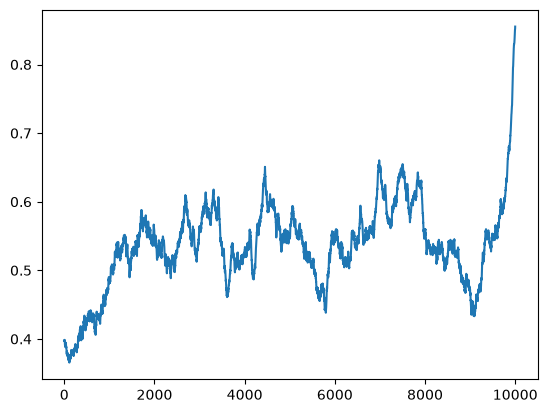

In [ ]:
episode_last_rewards = [reward[-1] for reward in rewards]


window_width =  251
pad = window_width //2

episode_last_rewards_p = np.pad(episode_last_rewards, pad, mode="edge")
roll_last_rewards = sliding_window_view(episode_last_rewards_p, window_width).mean(axis=1)

plt.plot(roll_last_rewards)

## Episode reward sum over training

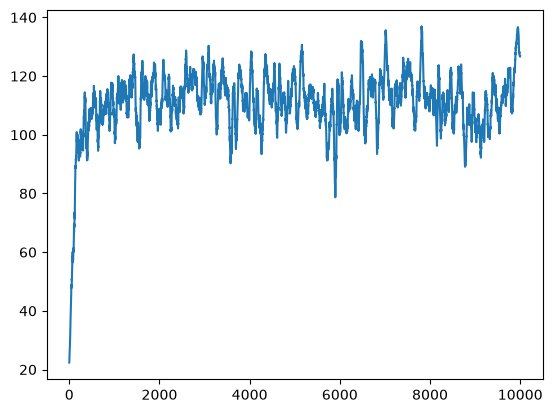

In [11]:
episode_rewards_sum = [sum(reward) for reward in rewards]


window_width =  51
pad = window_width //2

episode_rewards_sum_p = np.pad(episode_rewards_sum, pad, mode="edge")
roll_rewards_sum = sliding_window_view(episode_rewards_sum_p, window_width).mean(axis=1)

plt.plot(roll_rewards_sum)
# plt.plot(episode_rewards_sum)

## episode rewards average over training

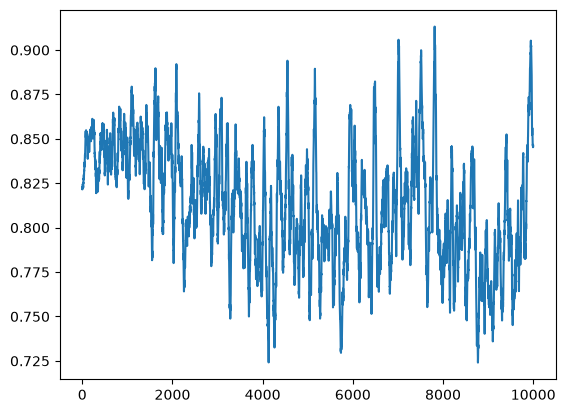

In [12]:
episode_rewards_avg = [np.mean(reward) for reward in rewards]


window_width =  51
pad = window_width //2

episode_rewards_avg_p = np.pad(episode_rewards_avg, pad, mode="edge")
roll_rewards_avg = sliding_window_view(episode_rewards_avg_p, window_width).mean(axis=1)

plt.plot(roll_rewards_avg)
# plt.plot(episode_rewards_sum)